# Exerciții de bagging (împachtare)

![Bagging.png](Assets/Bagging.png)

# Obiectivele învățării

- Asocierea conceptelor de bootstrapping și agregare (cunoscute sub denumirea de „bagging”) pentru reducerea varianței
- Aplicarea algoritmului Random Forest care reduce și mai mult corelația observată în modelele de tip bagging


## Introducere

Pentru exercițiile din această săptămână, vom utiliza datele privind pierderea clienților din industria telecomunicațiilor pe care le-am folosit în săptămâna 1. Fișierul de date se numește `Orange_Telecom_Churn_Data.csv`. 

In [1]:
from __future__ import print_function

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix



## Întrebarea 1

* Importați datele privind evoluția clienților, care se găsesc în fișierul `Orange_Telecom_Churn_Data.csv`. 
* Eliminați toate coloanele care nu sunt susceptibile de a fi utilizate pentru predicție.
* Codificați tipurile de date după caz.

Predicția cu siguranță nu ar trebui să includă numărul de telefon. Și este puțin probabil ca prefixul sau statul să fie dorit, cu excepția cazului în care există un motiv pentru a presupune că modelul are un factor geografic foarte specific.

Examinați tipurile de date. Totul pare în regulă, cu excepția faptului că `int_plan` și `voice_mail_plan` trebuie să fie codificate boolean.

In [2]:
import pandas as pd

df = pd.read_csv("Orange_Telecom_Churn_Data - Orange_Telecom_Churn_Data.csv")

df = df.drop(columns=["state", "area_code", "phone_number"])
df["intl_plan"] = df["intl_plan"].map({"yes": True, "no": False})
df["voice_mail_plan"] = df["voice_mail_plan"].map({"yes": True, "no": False})

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   account_length                 5000 non-null   int64  
 1   intl_plan                      5000 non-null   bool   
 2   voice_mail_plan                5000 non-null   bool   
 3   number_vmail_messages          5000 non-null   int64  
 4   total_day_minutes              5000 non-null   float64
 5   total_day_calls                5000 non-null   int64  
 6   total_day_charge               5000 non-null   float64
 7   total_eve_minutes              5000 non-null   float64
 8   total_eve_calls                5000 non-null   int64  
 9   total_eve_charge               5000 non-null   float64
 10  total_night_minutes            5000 non-null   float64
 11  total_night_calls              5000 non-null   int64  
 12  total_night_charge             5000 non-null   float64
 13 

,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,False,True,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,107,False,True,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,137,False,False,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,84,True,False,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,75,True,False,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


## Întrebarea 2

* Examinați distribuția variabilei prezise (`churned`).
* Împărțiți datele în seturi de instruire și de testare. Decideți dacă ar trebui utilizată sau nu o împărțire stratificată pe baza distribuției.
* Examinați distribuția variabilei predictor în datele de instruire și de testare.

Având în vedere dezechilibrul variabilei predictoare, să împărțim datele, valorile *churned* fiind stratificate.

In [3]:
import matplotlib.pyplot as plt

print("Distribuția variabilei churned:")
print(df["churned"].value_counts())
print(df["churned"].value_counts(normalize=True))

X = df.drop(columns=["churned"])
y = df["churned"]

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("\nDistribuția în setul de instruire:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nDistribuția în setul de testare:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

Distribuția variabilei churned:
churned
False    4293
True      707
Name: count, dtype: int64
churned
False    0.8586
True     0.1414
Name: proportion, dtype: float64

Distribuția în setul de instruire:
churned
False    3434
True      566
Name: count, dtype: int64
churned
False    0.8585
True     0.1415
Name: proportion, dtype: float64

Distribuția în setul de testare:
churned
False    859
True     141
Name: count, dtype: int64
churned
False    0.859
True     0.141
Name: proportion, dtype: float64


## Întrebare 3

* Potriviți modele de păduri aleatorii cu o serie de numere de arbori și evaluați eroarea din afara sacului pentru fiecare dintre aceste modele.
* Reprezentați grafic erorile oob rezultate ca funcție de numărul de arbori.

*Hint:* deoarece singurul lucru care se schimbă este numărul de arbori, se poate utiliza flagul `warm_start` astfel încât modelul să adauge de fiecare dată mai mulți arbori la modelul existent. Utilizați metoda `set_params` pentru a actualiza numărul de arbori.

In [4]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

,n_estimators,oob_error
0,10,0.06475
1,25,0.05100
2,50,0.04650
3,75,0.04325
4,100,0.04150
5,150,0.04125
6,200,0.04100
7,300,0.04175


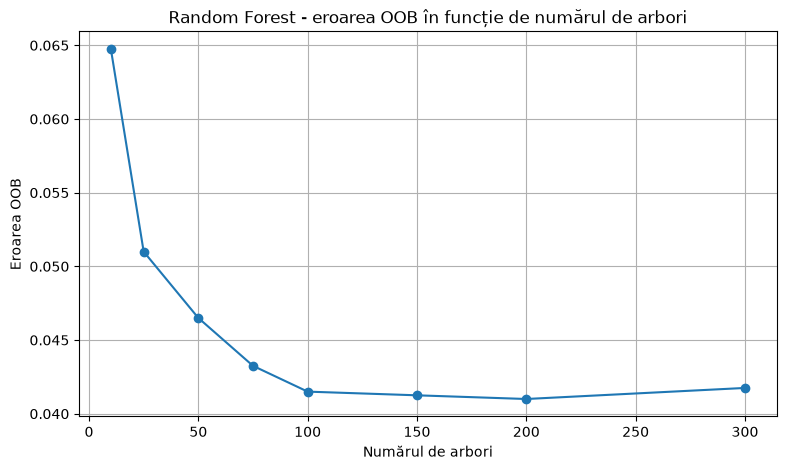

In [5]:
n_estimators_range = [10, 25, 50, 75, 100, 150, 200, 300]

rf_model = RandomForestClassifier(
    n_estimators=10,
    oob_score=True,
    bootstrap=True,
    warm_start=True,
    random_state=42,
    n_jobs=-1
)

rf_oob_errors = []

for n_trees in n_estimators_range:
    rf_model.set_params(n_estimators=n_trees)
    rf_model.fit(X_train, y_train)
    rf_oob_errors.append(1 - rf_model.oob_score_)

rf_results = pd.DataFrame({
    "n_estimators": n_estimators_range,
    "oob_error": rf_oob_errors
})

display(rf_results)

plt.figure(figsize=(9, 5))
plt.plot(rf_results["n_estimators"], rf_results["oob_error"], marker="o")
plt.xlabel("Numărul de arbori")
plt.ylabel("Eroarea OOB")
plt.title("Random Forest - eroarea OOB în funcție de numărul de arbori")
plt.grid(True)
plt.show()

## Întrebarea 4

* Repetați întrebarea 3 folosind arbori extra randomizați (`ExtraTreesClassifier`). Rețineți că parametrul `bootstrap` va trebui să fie setat la `True` pentru acest model.
* Comparați erorile de ieșire din sac pentru cele două tipuri diferite de modele.

,n_estimators,oob_error
0,10,0.09375
1,25,0.07375
2,50,0.06250
3,75,0.06100
4,100,0.05725
5,150,0.05800
6,200,0.05675
7,300,0.05775


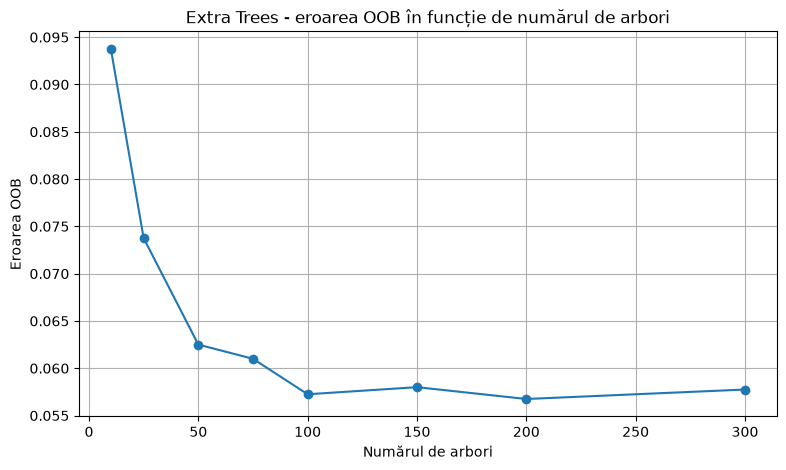

In [6]:
et_model = ExtraTreesClassifier(
    n_estimators=10,
    oob_score=True,
    bootstrap=True,
    warm_start=True,
    random_state=42,
    n_jobs=-1
)

et_oob_errors = []

for n_trees in n_estimators_range:
    et_model.set_params(n_estimators=n_trees)
    et_model.fit(X_train, y_train)
    et_oob_errors.append(1 - et_model.oob_score_)

et_results = pd.DataFrame({
    "n_estimators": n_estimators_range,
    "oob_error": et_oob_errors
})

display(et_results)

plt.figure(figsize=(9, 5))
plt.plot(et_results["n_estimators"], et_results["oob_error"], marker="o")
plt.xlabel("Numărul de arbori")
plt.ylabel("Eroarea OOB")
plt.title("Extra Trees - eroarea OOB în funcție de numărul de arbori")
plt.grid(True)
plt.show()

Combină cele două cadre de date într-unul singur pentru a ușura trasarea.

,n_estimators,oob_error,model
0,10,0.06475,Random Forest
1,25,0.05100,Random Forest
2,50,0.04650,Random Forest
3,75,0.04325,Random Forest
4,100,0.04150,Random Forest
5,150,0.04125,Random Forest
6,200,0.04100,Random Forest
7,300,0.04175,Random Forest
8,10,0.09375,Extra Trees
9,25,0.07375,Extra Trees


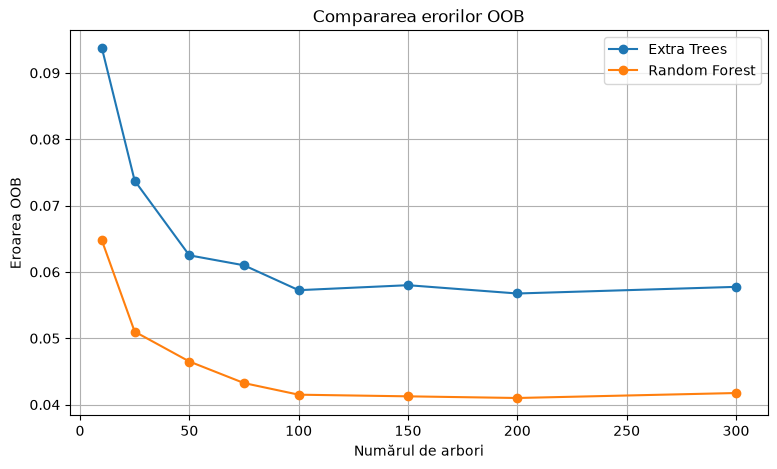

In [7]:
oob_comparison = pd.concat([
    rf_results.assign(model="Random Forest"),
    et_results.assign(model="Extra Trees")
], ignore_index=True)

display(oob_comparison)

plt.figure(figsize=(9, 5))
for model_name, model_data in oob_comparison.groupby("model"):
    plt.plot(model_data["n_estimators"], model_data["oob_error"], marker="o", label=model_name)

plt.xlabel("Numărul de arbori")
plt.ylabel("Eroarea OOB")
plt.title("Compararea erorilor OOB")
plt.legend()
plt.grid(True)
plt.show()

Modelul de pădure aleatorie are în mod constant rezultate mai bune decât arborii randomizați suplimentari.

## Întrebarea 5

* Selectați unul dintre modelele care se comportă bine și calculați parametrii de eroare și o matrice de confuzie pe setul de date de test. 
* Având în vedere distribuția clasei prezise, care metrică este cea mai importantă? Care ar putea fi înșelătoare?

In [8]:
best_rf_n = int(rf_results.loc[rf_results["oob_error"].idxmin(), "n_estimators"])

best_model = RandomForestClassifier(
    n_estimators=best_rf_n,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Numărul de arbori selectat:", best_rf_n)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Matricea de confuzie:")
print(confusion_matrix(y_test, y_pred))

Numărul de arbori selectat: 200
Accuracy: 0.959
Precision: 0.9310344827586207
Recall: 0.7659574468085106
F1-score: 0.8404669260700389

Classification report:
              precision    recall  f1-score   support

       False       0.96      0.99      0.98       859
        True       0.93      0.77      0.84       141

    accuracy                           0.96      1000
   macro avg       0.95      0.88      0.91      1000
weighted avg       0.96      0.96      0.96      1000

Matricea de confuzie:
[[851   8]
 [ 33 108]]


Nu este surprinzător faptul că reamintirea este destul de slabă pentru clasa clienților care au renunțat (Adevărat), deoarece aceștia sunt destul de mici. Totuși, ne descurcăm mai bine decât ghicirile aleatorii, deoarece precizia este de 0,932 (față de 0,85 pentru ghicirile aleatorii).

## Întrebare 6

* Tipăriți sau vizualizați matricea de confuzie.
* Reprezentați grafic curbele ROC-AUC și precizie-rechemare.
* Reprezentarea grafică a importanței caracteristicilor.

Matricea de confuzie:
[[851   8]
 [ 33 108]]


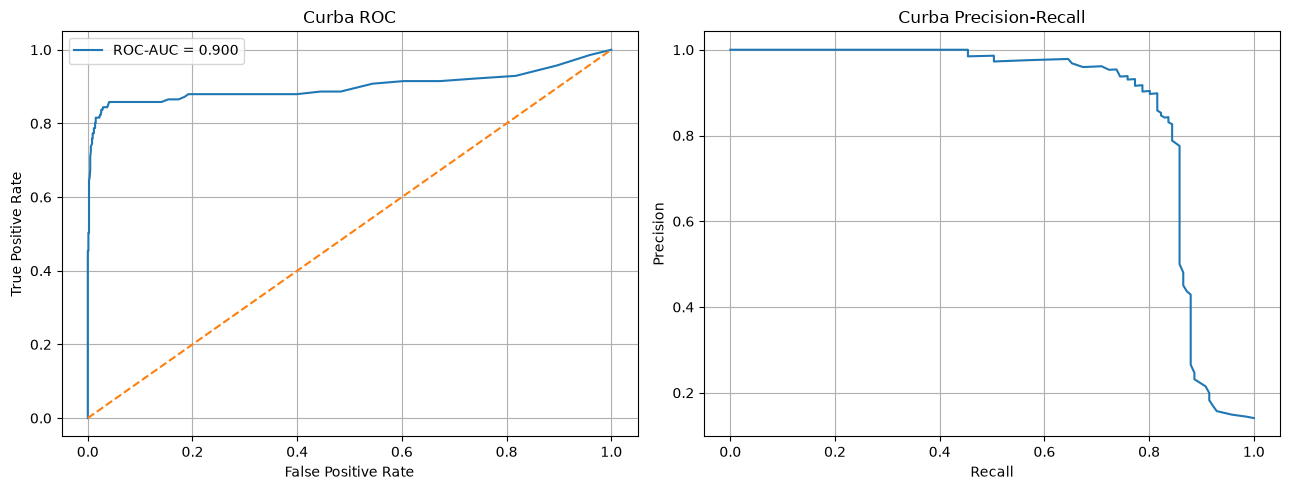

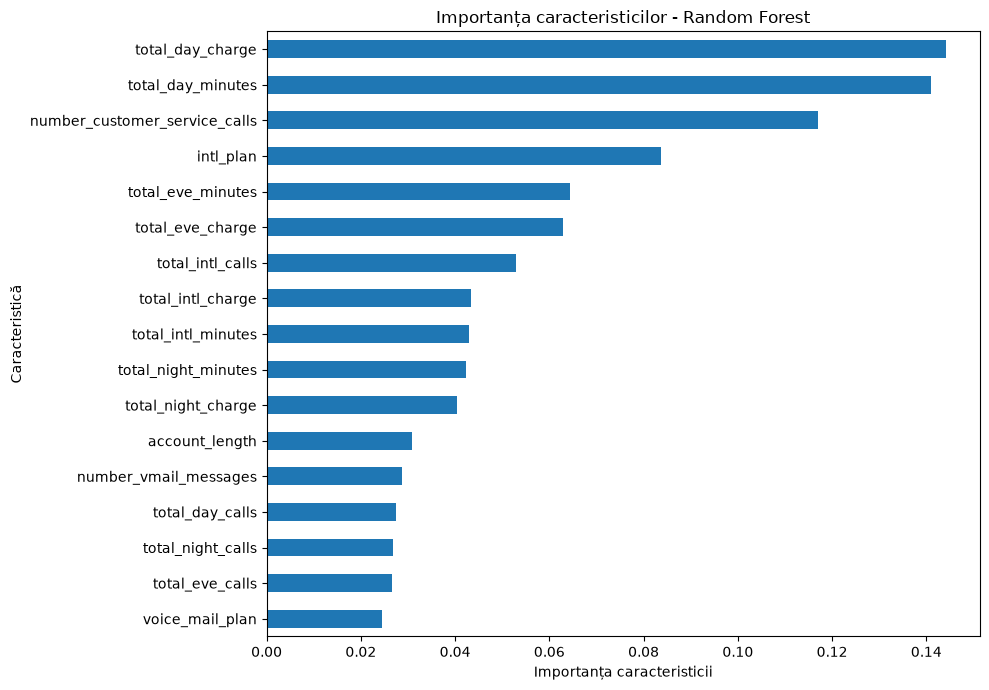

In [9]:
y_proba = best_model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)

print("Matricea de confuzie:")
print(cm)

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

precision_values, recall_values, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Curba ROC")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(recall_values, precision_values)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Curba Precision-Recall")
axes[1].grid(True)

plt.tight_layout()
plt.show()

feature_importances = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
feature_importances.plot(kind="barh")
plt.xlabel("Importanța caracteristicii")
plt.ylabel("Caracteristică")
plt.title("Importanța caracteristicilor - Random Forest")
plt.tight_layout()
plt.show()